# UCS420: Cognitive Computing
## Assignment 7 — NLP-I

In [1]:
import re
import string
import random
import hashlib
import math
import warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.tokenize import sent_tokenize, word_tokenize, RegexpTokenizer
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
warnings.filterwarnings("ignore")
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4", "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 120)

## Starter cell (replace with the cell from UCS420_LA9_Starter.ipynb)

In [2]:
ROLL_NUMBER = input("Enter your roll number: ").strip()

def generate_dataset(roll):
    seed = int(hashlib.md5(roll.encode()).hexdigest(), 16) % (10 ** 8)
    rnd = random.Random(seed)
    users = ["amit", "neha", "ravi", "sara", "john", "priya"]
    hosts = ["corp-mail.com", "helpdesk.org", "campus.edu"]
    sites = ["https://support.example.com/kb/123", "http://status.corp.net/incidents", "www.vpn-portal.org/login"]
    phones = ["+91-98765-43210", "(555) 123-4567", "555-987-6543", "9876543210"]
    versions = ["2.0.1", "3.4.2", "1.12.0", "10.0.19"]
    templates = [
        "User {u}@{h} reports that the Wi-Fi isn't working since version {v}. Call {p} for details.",
        "The VPN client {v} crashed 3 times. Please check {s} and reply to {u}@{h}.",
        "Printer on floor 4 is printing blank pages. Signal strength dropped to 95.5 percent. Contact {p}.",
        "Users cannot login to the portal after the update. Error rates reached 12.5 percent. See {s}.",
        "Email {u}@{h} bounced twice. The state-of-the-art firewall is blocking messages. Call {p} urgently.",
        "Laptop battery is draining quickly after installing version {v}. Technicians are investigating the issue.",
        "Application crashes whenever uploading large files. Engineers have identified a memory leak in build {v}.",
        "Outlook keeps asking for passwords. Administrators reset the accounts, but it isn't fixed. Visit {s}.",
        "Network drops every 15 minutes in Building A. Technicians replaced the cables and updated the routers.",
        "Backup jobs were failing at 98.7 percent completion. Please escalate to {u}@{h} or call {p}.",
        "Users reported slow responses from the database servers. Monitoring shows increasing latency and timeouts.",
        "Unable to connect to the shared drive. Mapping drives fails with error 0x80070035 on version {v}.",
        "Keyboard is not detected after the driver updated. Replacing it didn't help, so ticket {n} was opened.",
        "Software licenses are expiring tomorrow. Managers requested renewals through {s} and {u}@{h}.",
    ]
    count = rnd.randint(12, 16)
    out = []
    for i in range(count):
        t = templates[i % len(templates)]
        out.append(t.format(u=rnd.choice(users), h=rnd.choice(hosts), v=rnd.choice(versions), p=rnd.choice(phones), s=rnd.choice(sites), n=rnd.randint(1000, 9999)))
    return out

STOP = set(stopwords.words("english"))
PUNCT = set(string.punctuation) | {"``", "''", "--", "...", "\u2019", "\u201c", "\u201d"}

def process_ticket(text):
    sentences = sent_tokenize(text)
    tokens = word_tokenize(text)
    punctuation = [t for t in tokens if all(ch in PUNCT for ch in t)]
    stop = [t for t in tokens if t.lower() in STOP]
    final = [t.lower() for t in tokens if t not in punctuation and t.lower() not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punctuation": punctuation, "stopwords": stop, "final": final}

TEST_LINES = [
    "Contact john.doe@mail.example.com or support@help-desk.org for the Wi-Fi isn't working issue.",
    "Visit https://www.example.com/path?x=1 or www.test-site.org for version 2.0.1 notes.",
    "Call +91-98765-43210, (555) 123-4567 or 555-987-6543 about the 95.5 percent failure.",
    "The state-of-the-art Router Isn't Active; Alice and Ethan use Oracle 3.14 daily.",
]

tickets = generate_dataset(ROLL_NUMBER)
print("Fingerprint:", hashlib.sha256(("".join(tickets)).encode()).hexdigest()[:8])
print(len(tickets), "tickets")
for i, t in enumerate(tickets, 1):
    print(i, t)

Fingerprint: b05bb722
14 tickets
1 User sara@campus.edu reports that the Wi-Fi isn't working since version 10.0.19. Call +91-98765-43210 for details.
2 The VPN client 2.0.1 crashed 3 times. Please check www.vpn-portal.org/login and reply to sara@campus.edu.
3 Printer on floor 4 is printing blank pages. Signal strength dropped to 95.5 percent. Contact 9876543210.
4 Users cannot login to the portal after the update. Error rates reached 12.5 percent. See https://support.example.com/kb/123.
5 Email neha@campus.edu bounced twice. The state-of-the-art firewall is blocking messages. Call 9876543210 urgently.
6 Laptop battery is draining quickly after installing version 2.0.1. Technicians are investigating the issue.
7 Application crashes whenever uploading large files. Engineers have identified a memory leak in build 2.0.1.
8 Outlook keeps asking for passwords. Administrators reset the accounts, but it isn't fixed. Visit https://support.example.com/kb/123.
9 Network drops every 15 minutes in 

## 1. Preprocessing

In [3]:
processed = [process_ticket(t) for t in tickets]
rows = []
for i, p in enumerate(processed, 1):
    rows.append({
        "Ticket": i,
        "Sentences": len(p["sentences"]),
        "Tokens": len(p["tokens"]),
        "Punctuation Tokens": len(p["punctuation"]),
        "Stopwords": len(p["stopwords"]),
        "Unique Tokens": len(set(p["tokens"])),
        "Final Tokens": len(p["final"]),
    })
df1 = pd.DataFrame(rows)
total = {c: df1[c].sum() for c in df1.columns if c != "Ticket"}
total["Ticket"] = "Total"
df1 = pd.concat([df1, pd.DataFrame([total])], ignore_index=True)
df1

,Ticket,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,1,2,20,3,4,19,13
1,2,2,18,3,3,17,12
2,3,3,19,3,3,17,13
3,4,3,22,4,6,19,12
4,5,3,18,4,2,16,12
5,6,2,16,2,4,15,10
6,7,2,17,2,3,16,12
7,8,3,22,5,5,20,12
8,9,1,17,1,4,16,12
9,10,2,19,3,4,18,12


In [4]:
sel = 0
p = processed[sel]
print("Selected ticket:", sel + 1)
print(tickets[sel])
print()
print("Tokens           :", p["tokens"])
print("Punctuation      :", p["punctuation"])
print("Stopwords        :", p["stopwords"])
print("Final tokens     :", p["final"])

Selected ticket: 1
User sara@campus.edu reports that the Wi-Fi isn't working since version 10.0.19. Call +91-98765-43210 for details.

Tokens           : ['User', 'sara', '@', 'campus.edu', 'reports', 'that', 'the', 'Wi-Fi', 'is', "n't", 'working', 'since', 'version', '10.0.19', '.', 'Call', '+91-98765-43210', 'for', 'details', '.']
Punctuation      : ['@', '.', '.']
Stopwords        : ['that', 'the', 'is', 'for']
Final tokens     : ['user', 'sara', 'campus.edu', 'reports', 'wi-fi', "n't", 'working', 'since', 'version', '10.0.19', 'call', '+91-98765-43210', 'details']


## 2. Regex extraction and replacement

In [5]:
RE_LONG = r"\b[A-Za-z]{6,}\b"
RE_NUM = r"(?<![\w.])\d+(?:\.\d+)*(?![\w])"
RE_CAP = r"\b[A-Z][a-z]*\b"
RE_VOWEL = r"\b[AEIOUaeiou][A-Za-z]*\b"

RE_EMAIL = r"[\w.+-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+"
RE_URL = r"(?:https?://|www\.)[^\s<>\"']*[^\s<>\"'.,;:!?)]"
RE_PHONE = r"(?<![\w.])(?:\+\d{1,3}[\s-]?\d{5}[\s-]?\d{5}|(?:\+\d{1,3}[\s.-]?)?(?:\(\d{3}\)|\d{3})[\s.-]?\d{3}[\s.-]?\d{4})(?!\d)"

def extract_all(text):
    return {
        "long_words": re.findall(RE_LONG, text),
        "numbers": re.findall(RE_NUM, mask(text)),
        "capitalized": re.findall(RE_CAP, text),
        "vowel_start": re.findall(RE_VOWEL, text),
    }

def mask(text):
    text = re.sub(RE_EMAIL, "<EMAIL>", text)
    text = re.sub(RE_URL, "<URL>", text)
    text = re.sub(RE_PHONE, "<PHONE>", text)
    return text

for line in TEST_LINES:
    print("LINE    :", line)
    for k, v in extract_all(line).items():
        print(f"  {k:12s}:", v)
    print("  masked      :", mask(line))
    print()

LINE    : Contact john.doe@mail.example.com or support@help-desk.org for the Wi-Fi isn't working issue.
  long_words  : ['Contact', 'example', 'support', 'working']
  numbers     : []
  capitalized : ['Contact', 'Wi', 'Fi']
  vowel_start : ['example', 'or', 'org', 'isn', 'issue']
  masked      : Contact <EMAIL> or <EMAIL> for the Wi-Fi isn't working issue.

LINE    : Visit https://www.example.com/path?x=1 or www.test-site.org for version 2.0.1 notes.
  long_words  : ['example', 'version']
  numbers     : ['2.0.1']
  capitalized : ['Visit']
  vowel_start : ['example', 'or', 'org']
  masked      : Visit <URL> or <URL> for version 2.0.1 notes.

LINE    : Call +91-98765-43210, (555) 123-4567 or 555-987-6543 about the 95.5 percent failure.
  long_words  : ['percent', 'failure']
  numbers     : ['95.5']
  capitalized : ['Call']
  vowel_start : ['or', 'about']
  masked      : Call <PHONE>, <PHONE> or <PHONE> about the 95.5 percent failure.

LINE    : The state-of-the-art Router Isn't Active; 

In [6]:
rows = []
for i, t in enumerate(tickets, 1):
    e = extract_all(t)
    rows.append({"Ticket": i, "Long words": e["long_words"], "Numbers": e["numbers"], "Capitalized": e["capitalized"], "Vowel-start": e["vowel_start"]})
pd.DataFrame(rows)

,Ticket,Long words,Numbers,Capitalized,Vowel-start
0,1,"[campus, reports, working, version, details]",[10.0.19],"[User, Wi, Fi, Call]","[User, edu, isn]"
1,2,"[client, crashed, Please, portal, campus]","[2.0.1, 3]","[The, Please]","[org, and, edu]"
2,3,"[Printer, printing, Signal, strength, dropped, percent, Contact]","[4, 95.5]","[Printer, Signal, Contact]","[on, is]"
3,4,"[cannot, portal, update, reached, percent, support, example]",[12.5],"[Users, Error, See]","[Users, after, update, Error, example]"
4,5,"[campus, bounced, firewall, blocking, messages, urgently]",[],"[Email, The, Call]","[Email, edu, of, art, is, urgently]"
5,6,"[Laptop, battery, draining, quickly, installing, version, Technicians, investigating]",[2.0.1],"[Laptop, Technicians]","[is, after, installing, are, investigating, issue]"
6,7,"[Application, crashes, whenever, uploading, Engineers, identified, memory]",[2.0.1],"[Application, Engineers]","[Application, uploading, Engineers, identified, a, in]"
7,8,"[Outlook, asking, passwords, Administrators, accounts, support, example]",[],"[Outlook, Administrators, Visit]","[Outlook, asking, Administrators, accounts, it, isn, example]"
8,9,"[Network, minutes, Building, Technicians, replaced, cables, updated, routers]",[15],"[Network, Building, A, Technicians]","[every, in, A, and, updated]"
9,10,"[Backup, failing, percent, completion, Please, escalate, helpdesk]",[98.7],"[Backup, Please]","[at, escalate, org, or]"


In [7]:
pd.DataFrame({"Original": tickets, "Masked": [mask(t) for t in tickets]})

,Original,Masked
0,User sara@campus.edu reports that the Wi-Fi isn't working since version 10.0.19. Call +91-98765-43210 for details.,User <EMAIL> reports that the Wi-Fi isn't working since version 10.0.19. Call <PHONE> for details.
1,The VPN client 2.0.1 crashed 3 times. Please check www.vpn-portal.org/login and reply to sara@campus.edu.,The VPN client 2.0.1 crashed 3 times. Please check <URL> and reply to <EMAIL>.
2,Printer on floor 4 is printing blank pages. Signal strength dropped to 95.5 percent. Contact 9876543210.,Printer on floor 4 is printing blank pages. Signal strength dropped to 95.5 percent. Contact <PHONE>.
3,Users cannot login to the portal after the update. Error rates reached 12.5 percent. See https://support.example.com...,Users cannot login to the portal after the update. Error rates reached 12.5 percent. See <URL>.
4,Email neha@campus.edu bounced twice. The state-of-the-art firewall is blocking messages. Call 9876543210 urgently.,Email <EMAIL> bounced twice. The state-of-the-art firewall is blocking messages. Call <PHONE> urgently.
5,Laptop battery is draining quickly after installing version 2.0.1. Technicians are investigating the issue.,Laptop battery is draining quickly after installing version 2.0.1. Technicians are investigating the issue.
6,Application crashes whenever uploading large files. Engineers have identified a memory leak in build 2.0.1.,Application crashes whenever uploading large files. Engineers have identified a memory leak in build 2.0.1.
7,"Outlook keeps asking for passwords. Administrators reset the accounts, but it isn't fixed. Visit https://support.exa...","Outlook keeps asking for passwords. Administrators reset the accounts, but it isn't fixed. Visit <URL>."
8,Network drops every 15 minutes in Building A. Technicians replaced the cables and updated the routers.,Network drops every 15 minutes in Building A. Technicians replaced the cables and updated the routers.
9,Backup jobs were failing at 98.7 percent completion. Please escalate to john@helpdesk.org or call +91-98765-43210.,Backup jobs were failing at 98.7 percent completion. Please escalate to <EMAIL> or call <PHONE>.


## 3. Custom tokenization

In [8]:
TOKEN_PATTERN = (
    r"(?:https?://|www\.)[^\s<>\"']*[^\s<>\"'.,;:!?)]"
    r"|[\w.+-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+"
    r"|(?<![\w.])(?:\+\d{1,3}[\s-]?\d{5}[\s-]?\d{5}|(?:\+\d{1,3}[\s.-]?)?(?:\(\d{3}\)|\d{3})[\s.-]?\d{3}[\s.-]?\d{4})(?!\d)"
    r"|\d+(?:\.\d+)+"
    r"|\w+(?:['\u2019]\w+)*(?:-\w+(?:['\u2019]\w+)*)*"
    r"|[^\w\s]"
)
_tok = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    return _tok.tokenize(text)

for line in TEST_LINES:
    print("LINE        :", line)
    print("my_tokenize :", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))
    print()

LINE        : Contact john.doe@mail.example.com or support@help-desk.org for the Wi-Fi isn't working issue.
my_tokenize : ['Contact', 'john.doe@mail.example.com', 'or', 'support@help-desk.org', 'for', 'the', 'Wi-Fi', "isn't", 'working', 'issue', '.']
word_tokenize: ['Contact', 'john.doe', '@', 'mail.example.com', 'or', 'support', '@', 'help-desk.org', 'for', 'the', 'Wi-Fi', 'is', "n't", 'working', 'issue', '.']

LINE        : Visit https://www.example.com/path?x=1 or www.test-site.org for version 2.0.1 notes.
my_tokenize : ['Visit', 'https://www.example.com/path?x=1', 'or', 'www.test-site.org', 'for', 'version', '2.0.1', 'notes', '.']
word_tokenize: ['Visit', 'https', ':', '//www.example.com/path', '?', 'x=1', 'or', 'www.test-site.org', 'for', 'version', '2.0.1', 'notes', '.']

LINE        : Call +91-98765-43210, (555) 123-4567 or 555-987-6543 about the 95.5 percent failure.
my_tokenize : ['Call', '+91-98765-43210', ',', '(555) 123-4567', 'or', '555-987-6543', 'about', 'the', '95.5', '

In [9]:
for i, t in enumerate(tickets, 1):
    print(i, my_tokenize(t))

1 ['User', 'sara@campus.edu', 'reports', 'that', 'the', 'Wi-Fi', "isn't", 'working', 'since', 'version', '10.0.19', '.', 'Call', '+91-98765-43210', 'for', 'details', '.']
2 ['The', 'VPN', 'client', '2.0.1', 'crashed', '3', 'times', '.', 'Please', 'check', 'www.vpn-portal.org/login', 'and', 'reply', 'to', 'sara@campus.edu', '.']
3 ['Printer', 'on', 'floor', '4', 'is', 'printing', 'blank', 'pages', '.', 'Signal', 'strength', 'dropped', 'to', '95.5', 'percent', '.', 'Contact', '9876543210', '.']
4 ['Users', 'cannot', 'login', 'to', 'the', 'portal', 'after', 'the', 'update', '.', 'Error', 'rates', 'reached', '12.5', 'percent', '.', 'See', 'https://support.example.com/kb/123', '.']
5 ['Email', 'neha@campus.edu', 'bounced', 'twice', '.', 'The', 'state-of-the-art', 'firewall', 'is', 'blocking', 'messages', '.', 'Call', '9876543210', 'urgently', '.']
6 ['Laptop', 'battery', 'is', 'draining', 'quickly', 'after', 'installing', 'version', '2.0.1', '.', 'Technicians', 'are', 'investigating', 'the'

In [10]:
diff_rows = []
for src, texts in (("TEST_LINES", TEST_LINES), ("tickets", tickets)):
    for idx, t in enumerate(texts, 1):
        a, b = my_tokenize(t), word_tokenize(t)
        ca, cb = Counter(a), Counter(b)
        only_mine = sorted((ca - cb).elements())
        only_nltk = sorted((cb - ca).elements())
        if only_mine or only_nltk:
            diff_rows.append({"Source": f"{src}[{idx}]", "Only my_tokenize": only_mine, "Only word_tokenize": only_nltk})
df3 = pd.DataFrame(diff_rows)
df3

,Source,Only my_tokenize,Only word_tokenize
0,TEST_LINES[1],"[isn't, john.doe@mail.example.com, support@help-desk.org]","[@, @, help-desk.org, is, john.doe, mail.example.com, n't, support]"
1,TEST_LINES[2],[https://www.example.com/path?x=1],"[//www.example.com/path, :, ?, https, x=1]"
2,TEST_LINES[3],[(555) 123-4567],"[(, ), 123-4567, 555]"
3,TEST_LINES[4],[Isn't],"[Is, n't]"
4,tickets[1],"[isn't, sara@campus.edu]","[@, campus.edu, is, n't, sara]"
5,tickets[2],[sara@campus.edu],"[@, campus.edu, sara]"
6,tickets[4],"[cannot, https://support.example.com/kb/123]","[//support.example.com/kb/123, :, can, https, not]"
7,tickets[5],[neha@campus.edu],"[@, campus.edu, neha]"
8,tickets[8],"[https://support.example.com/kb/123, isn't]","[//support.example.com/kb/123, :, https, is, n't]"
9,tickets[9],"[., A]",[A.]


In [11]:
def categorize(a, b):
    cats = []
    if any(x.lower().endswith("n't") or x.lower() in ("is", "n't") for x in b) and any("'" in x for x in a):
        cats.append("contraction")
    if any(x.startswith(("http", "www")) for x in a):
        cats.append("url")
    if any("@" in x and len(x) > 1 for x in a):
        cats.append("email")
    if any(re.fullmatch(r"[\d+() .-]{10,}", x) for x in a):
        cats.append("phone")
    return cats

cat_rows = []
for t in TEST_LINES + tickets:
    a, b = my_tokenize(t), word_tokenize(t)
    if a != b:
        cat_rows.append((categorize(a, b), t, a, b))

shown = set()
for cats, t, a, b in cat_rows:
    for c in cats:
        if c not in shown:
            shown.add(c)
            print("Category:", c)
            print("  text         :", t)
            print("  my_tokenize  :", [x for x in a if (c == "contraction" and "'" in x) or (c == "url" and x.startswith(("http", "www"))) or (c == "email" and "@" in x and len(x) > 1) or (c == "phone" and re.fullmatch(r"[\d+() .-]{10,}", x))])
            print("  word_tokenize:", b)
            print()

Category: contraction
  text         : Contact john.doe@mail.example.com or support@help-desk.org for the Wi-Fi isn't working issue.
  my_tokenize  : ["isn't"]
  word_tokenize: ['Contact', 'john.doe', '@', 'mail.example.com', 'or', 'support', '@', 'help-desk.org', 'for', 'the', 'Wi-Fi', 'is', "n't", 'working', 'issue', '.']

Category: email
  text         : Contact john.doe@mail.example.com or support@help-desk.org for the Wi-Fi isn't working issue.
  my_tokenize  : ['john.doe@mail.example.com', 'support@help-desk.org']
  word_tokenize: ['Contact', 'john.doe', '@', 'mail.example.com', 'or', 'support', '@', 'help-desk.org', 'for', 'the', 'Wi-Fi', 'is', "n't", 'working', 'issue', '.']

Category: url
  text         : Visit https://www.example.com/path?x=1 or www.test-site.org for version 2.0.1 notes.
  my_tokenize  : ['https://www.example.com/path?x=1', 'www.test-site.org']
  word_tokenize: ['Visit', 'https', ':', '//www.example.com/path', '?', 'x=1', 'or', 'www.test-site.org', 'for', 've

## 4. Stemming and lemmatization

In [12]:
unique_final = sorted({w for p in processed for w in p["final"]})

tag_map = {}
for p in processed:
    for w, tg in nltk.pos_tag(p["final"]):
        tag_map.setdefault(w, tg)

def wn_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

candidates = ["ing", "ed", "ly", "ion", "s"]
chosen, chosen_words = None, []
for suf in candidates:
    ws = [w for w in unique_final if w.endswith(suf) and len(w) > len(suf) + 2 and w.isalpha()]
    if len(ws) >= 2:
        chosen, chosen_words = suf, ws
        break

print("Chosen suffix:", chosen)
print("Supporting words from the dataset:", chosen_words)

Chosen suffix: ing
Supporting words from the dataset: ['asking', 'blocking', 'building', 'draining', 'expiring', 'failing', 'increasing', 'installing', 'investigating', 'mapping', 'monitoring', 'printing', 'replacing', 'uploading', 'working']


In [13]:
porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp = RegexpStemmer(chosen + "$", min=len(chosen) + 3)
lemmatizer = WordNetLemmatizer()

rows = []
for w in unique_final:
    rows.append({
        "Word": w,
        "POS": tag_map.get(w, "NN"),
        "Porter": porter.stem(w),
        "Lancaster": lancaster.stem(w),
        "Regexp": regexp.stem(w),
        "WordNet Lemma": lemmatizer.lemmatize(w, wn_pos(tag_map.get(w, "NN"))),
    })
df4 = pd.DataFrame(rows)
diff4 = df4[df4[["Porter", "Lancaster", "Regexp", "WordNet Lemma"]].nunique(axis=1) > 1].reset_index(drop=True)
print(len(df4), "unique final tokens,", len(diff4), "with differing outputs")
diff4

137 unique final tokens, 89 with differing outputs


,Word,POS,Porter,Lancaster,Regexp,WordNet Lemma
0,accounts,NNS,account,account,accounts,account
1,administrators,NNS,administr,admin,administrators,administrator
2,application,NN,applic,apply,application,application
3,battery,NN,batteri,battery,battery,battery
4,blocking,NN,block,block,block,blocking
...,...,...,...,...,...,...
84,user,NN,user,us,user,user
85,users,NNS,user,us,users,user
86,version,NN,version,vert,version,version
87,whenever,WRB,whenev,whenev,whenever,whenever


## 5. Corpus statistics

In [14]:
S1 = [t.lower() for p in processed for t in p["tokens"]]
S2 = [t.lower() for p in processed for t in p["tokens"] if t not in p["punctuation"]]
S3 = [t for p in processed for t in p["final"]]
S4 = [porter.stem(t) for t in S3]

sets = {"S1": S1, "S2": S2, "S3": S3, "S4": S4}
stat_rows = []
for name, s in sets.items():
    total_n, uniq = len(s), len(set(s))
    stat_rows.append({"Set": name, "Total Tokens": total_n, "Unique Tokens": uniq, "TTR": round(uniq / total_n, 4)})
stats = pd.DataFrame(stat_rows)
stats

,Set,Total Tokens,Unique Tokens,TTR
0,S1,261,166,0.6360
1,S2,220,162,0.7364
2,S3,163,137,0.8405
3,S4,163,128,0.7853


In [15]:
print("Top 10 words of S1:")
for w, c in Counter(S1).most_common(10):
    print(f"  {w!r:20} {c}")
print()
print("Top 10 words of S3:")
for w, c in Counter(S3).most_common(10):
    print(f"  {w!r:20} {c}")

Top 10 words of S1:
  '.'                  31
  'the'                12
  'is'                 6
  'to'                 6
  '@'                  5
  'and'                4
  'campus.edu'         3
  "n't"                3
  'version'            3
  'call'               3

Top 10 words of S3:
  'campus.edu'         3
  "n't"                3
  'version'            3
  'call'               3
  '2.0.1'              3
  'percent'            3
  'https'              3
  '//support.example.com/kb/123' 3
  'sara'               2
  '10.0.19'            2


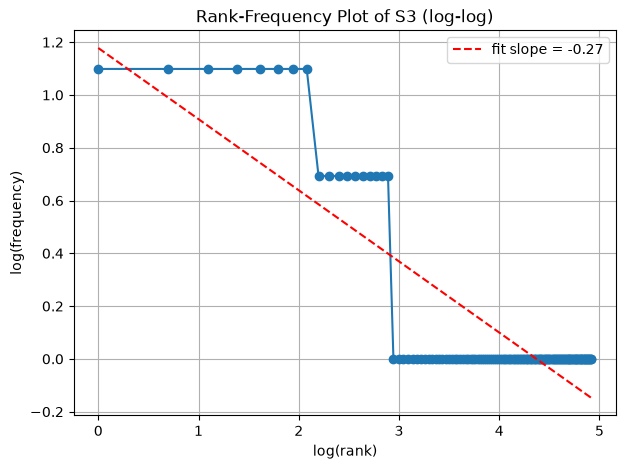

In [16]:
freq = sorted(Counter(S3).values(), reverse=True)
ranks = np.arange(1, len(freq) + 1)
plt.figure(figsize=(7, 5))
plt.plot(np.log(ranks), np.log(freq), marker="o", linestyle="-")
slope = np.polyfit(np.log(ranks), np.log(freq), 1)[0]
plt.plot(np.log(ranks), np.polyval(np.polyfit(np.log(ranks), np.log(freq), 1), np.log(ranks)), "r--", label=f"fit slope = {slope:.2f}")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Rank-Frequency Plot of S3 (log-log)")
plt.legend()
plt.grid(True)
plt.show()

In [17]:
print("Top 5 bigrams of S1:")
for bg, c in Counter(nltk.bigrams(S1)).most_common(5):
    print(f"  {bg}  {c}")
print()
print("Top 5 bigrams of S3:")
for bg, c in Counter(nltk.bigrams(S3)).most_common(5):
    print(f"  {bg}  {c}")

Top 5 bigrams of S1:
  ('@', 'campus.edu')  3
  ('https', ':')  3
  (':', '//support.example.com/kb/123')  3
  ('sara', '@')  2
  ('is', "n't")  2

Top 5 bigrams of S3:
  ('https', '//support.example.com/kb/123')  3
  ('sara', 'campus.edu')  2
  ('version', '10.0.19')  2
  ('call', '+91-98765-43210')  2
  ('user', 'sara')  1


## 6. Interpretation

In [18]:
t = stats.set_index("Set")["TTR"]
print("(a)")
print(f"TTR values: S1={t['S1']}, S2={t['S2']}, S3={t['S3']}, S4={t['S4']}.")
print(f"From S1 to S2 the TTR moves from {t['S1']} to {t['S2']} because repeated punctuation tokens (such as '.' and ',') are removed, which shrinks the token count much more than the number of types.")
print(f"From S2 to S3 it moves to {t['S3']} because high-frequency stopwords are removed, so the remaining tokens are more varied.")
print(f"From S3 to S4 it moves to {t['S4']} because stemming merges inflected variants into one type, reducing unique tokens while the token count stays the same.")

(a)
TTR values: S1=0.636, S2=0.7364, S3=0.8405, S4=0.7853.
From S1 to S2 the TTR moves from 0.636 to 0.7364 because repeated punctuation tokens (such as '.' and ',') are removed, which shrinks the token count much more than the number of types.
From S2 to S3 it moves to 0.8405 because high-frequency stopwords are removed, so the remaining tokens are more varied.
From S3 to S4 it moves to 0.7853 because stemming merges inflected variants into one type, reducing unique tokens while the token count stays the same.


In [19]:
print("(b)")
shown = False
for t_ in TEST_LINES + tickets:
    a, b = my_tokenize(t_), word_tokenize(t_)
    if any("'" in x and len(x) > 2 and x.lower().endswith("n't") for x in a):
        i = [k for k, x in enumerate(a) if x.lower().endswith("n't")][0]
        word = a[i]
        base = word[:-3]
        print(f"Text: {t_}")
        print(f"my_tokenize   -> {word!r}")
        print(f"word_tokenize -> {[x for x in b if x.lower() in (base.lower(), "n't", "ca", "wo")]}")
        print(f"word_tokenize splits the contraction into a base verb and n't (Penn Treebank style), while my_tokenize keeps {word!r} as one token because the pattern allows an apostrophe inside a word.")
        shown = True
        break
if not shown:
    for t_ in TEST_LINES + tickets:
        a, b = my_tokenize(t_), word_tokenize(t_)
        if a != b:
            print(f"Text: {t_}\nmy_tokenize -> {a}\nword_tokenize -> {b}")
            break

(b)
Text: Contact john.doe@mail.example.com or support@help-desk.org for the Wi-Fi isn't working issue.
my_tokenize   -> "isn't"
word_tokenize -> ['is', "n't"]
word_tokenize splits the contraction into a base verb and n't (Penn Treebank style), while my_tokenize keeps "isn't" as one token because the pattern allows an apostrophe inside a word.


In [20]:
print("(c)")
by_stem = {}
for w in unique_final:
    by_stem.setdefault(porter.stem(w), []).append(w)
over = [(s, ws) for s, ws in by_stem.items() if len(ws) > 1 and all(x.isalpha() for x in ws)]
non_word = [(w, porter.stem(w)) for w in unique_final if w.isalpha() and len(porter.stem(w)) > 2 and not wordnet.synsets(porter.stem(w)) and porter.stem(w) != w]
if over:
    s, ws = over[0]
    print(f"Porter maps different words {ws} to the same stem {s!r}, merging terms that are not always interchangeable (over-stemming).")
elif non_word:
    w, s = non_word[0]
    print(f"Porter stems {w!r} to {s!r}, which is not a valid English word and loses readability.")
if non_word:
    w, s = non_word[0]
    print(f"Another example: {w!r} -> {s!r} is not a dictionary word.")

(c)
Porter maps different words ['build', 'building'] to the same stem 'build', merging terms that are not always interchangeable (over-stemming).
Another example: 'administrators' -> 'administr' is not a dictionary word.


In [21]:
print("(d)")
printed = False
for w in [x for x in unique_final if x.isalpha()]:
    pos = tag_map.get(w, "NN")
    lem = lemmatizer.lemmatize(w, wn_pos(pos))
    st = porter.stem(w)
    if lem != w and wordnet.synsets(lem) and not wordnet.synsets(st) and lem != st:
        print(f"{w!r} (POS {pos}): POS-aware lemma = {lem!r}, Porter stem = {st!r}.")
        print(f"The lemma is a valid word carrying the correct meaning, while the stem {st!r} is a truncated form that is not a word.")
        printed = True
        break
if not printed:
    for w in unique_final:
        pos = tag_map.get(w, "NN")
        lem = lemmatizer.lemmatize(w, wn_pos(pos))
        if lem != porter.stem(w):
            print(f"{w!r} (POS {pos}): lemma = {lem!r}, Porter stem = {porter.stem(w)!r}.")
            print("The POS-aware lemma is a dictionary word that keeps the meaning, while the stem is a truncated form.")
            break

(d)
'administrators' (POS NNS): POS-aware lemma = 'administrator', Porter stem = 'administr'.
The lemma is a valid word carrying the correct meaning, while the stem 'administr' is a truncated form that is not a word.
